# 02 · The BARQ X gate on a three-level system

Notebook 01 designed the X gate for an ideal qubit. Here the same pulse
drives a three-level ladder $|0\rangle, |1\rangle, |2\rangle$, which adds
two effects:

- **Leakage:** population ends in $|2\rangle$.
- **Stark shift:** the $|1\rangle$–$|2\rangle$ coupling shifts the qubit
  frequency, which shows up as a coherent error inside the qubit.

Run notebook 01 first; it writes `data/xgate_barq_points.csv`.

## The model

The simulator integrates, in normalized time $s=t/T_g$,

$$
H(s)=T_g\Big[\tfrac{\Omega}{2}\big(\cos\Phi\,H_x+\sin\Phi\,H_y\big)+\Delta\,H_\Delta+\alpha\,|2\rangle\langle2|\Big],
\qquad
H_x=\tfrac12\begin{pmatrix}0&1&0\\1&0&\lambda\\0&\lambda&0\end{pmatrix},\quad
H_\Delta=\mathrm{diag}\big(\tfrac12,-\tfrac12,-\tfrac32\big).
$$

The $\{|0\rangle,|1\rangle\}$ block is exactly the qubit Hamiltonian of
notebook 01.

**Do we need a gate time?** Yes, but only through the product $T_g\alpha$.
The pulse is fixed in units of $T_g$, so a shorter gate means a larger peak
drive compared with $\alpha$, and more leakage. The cells below take a
transmon-like $\alpha/2\pi=-200$ MHz and $\lambda=\sqrt2$ from
`xgate_setup.py`, and convert each gate time into $T_g\alpha$ and a peak
drive.

**Is it only for a transmon?** No. `lam` and $\alpha$ are free parameters,
so any ladder-type three-level system whose drive couples only neighbouring
levels can be modelled. Dephasing noise is added to $\Delta$, which shifts
the levels by $(\tfrac12,-\tfrac12,-\tfrac32)\delta_z$. That is frequency
noise proportional to the excitation number, as in a transmon.

The model does not cover:
- a direct $|0\rangle$–$|2\rangle$ drive,
- $\Lambda$-type level schemes,
- noise that shifts the levels non-linearly,
- a fourth level, which matters only for very strong drives.

In [1]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from qurveros import drag, plottools
from qurveros.qubit_bench import noise_experiments, simulator
import qurveros.plot_configs

import xgate_setup as xs

matplotlib.rcParams['figure.dpi'] = 150

u_target = xs.U_TARGET
control_dict = xs.xgate_control()
tg_alpha = xs.tg_alpha(xs.GATE_TIME_NS)

pd.DataFrame({
    'T_g alpha': [xs.tg_alpha(t) for t in xs.GATE_TIMES_NS],
    'Omega_max / 2pi (MHz)': [xs.peak_drive_mhz(control_dict, t) for t in xs.GATE_TIMES_NS],
    'Omega_max / |alpha|': [xs.peak_drive_mhz(control_dict, t) / abs(xs.ALPHA_MHZ)
                            for t in xs.GATE_TIMES_NS],
}, index=pd.Index(xs.GATE_TIMES_NS, name='T_g (ns)'))

,T_g alpha,Omega_max / 2pi (MHz),Omega_max / |alpha|
T_g (ns),,,
30.0,-37.699112,75.890127,0.379451
50.0,-62.831853,45.534076,0.227670
80.0,-100.530965,28.458798,0.142294
120.0,-150.796447,18.972532,0.094863


## Leakage at $T_g = 50$ ns

`simulate_qutrit` returns:
- the final leakage $L=\tfrac12\big(|U_{20}|^2+|U_{21}|^2\big)$, also split
  by input state,
- the peak leakage during the pulse,
- the subspace infidelity of the $2\times2$ block,
- the subspace phase.

`xgate_setup.error_budget` splits the subspace infidelity into leakage and
the coherent error that stays inside the qubit. It does this by
polar-decomposing the block.

In [2]:
qutrit = simulator.simulate_qutrit(control_dict, u_target, tg_alpha, lam=xs.LAM)
budget = xs.error_budget(qutrit['u_final'], u_target)
first_order = drag.first_order_leakage(control_dict, tg_alpha, lam=xs.LAM)

pd.Series({
    'final leakage L': qutrit['leakage'],
    '  from |0>': qutrit['leakage_from_0'],
    '  from |1>': qutrit['leakage_from_1'],
    'peak leakage during the pulse': qutrit['peak_leakage'],
    'subspace infidelity': qutrit['subspace_infidelity'],
    '  coherent part (inside the qubit)': budget['coherent_infidelity'],
    '  leakage + coherent': budget['leakage'] + budget['coherent_infidelity'],
    'subspace phase (rad)': qutrit['subspace_phase'],
    'first-order leakage (calculated)': first_order['leakage'],
    'first-order peak leakage (calculated)': first_order['leakage_trace'].max(),
    'Fourier proxy estimate_leakage': drag.estimate_leakage(control_dict, tg_alpha, lam=xs.LAM),
}).to_frame('T_g = 50 ns')

,T_g = 50 ns
final leakage L,0.020133
from |0>,0.014187
from |1>,0.026079
peak leakage during the pulse,0.051293
subspace infidelity,0.027106
coherent part (inside the qubit),0.007047
leakage + coherent,0.027180
subspace phase (rad),0.947618
first-order leakage (calculated),0.015240
first-order peak leakage (calculated),0.058181


### Where the leakage happens

The $|2\rangle$ population over time, starting from $|0\rangle$ and from
$|1\rangle$. Solid lines are the simulation. The dashed line is the
calculated first-order leakage
$A_j(s)=-i\frac{\lambda}{2}\int_0^s T_g\varepsilon\,e^{i\theta_2}\langle1|U_q|j\rangle\,ds'$,
which uses the exact qubit evolution $U_q$.

Most of the population that reaches $|2\rangle$ during the pulse comes back.
The leakage error is what remains at the end.

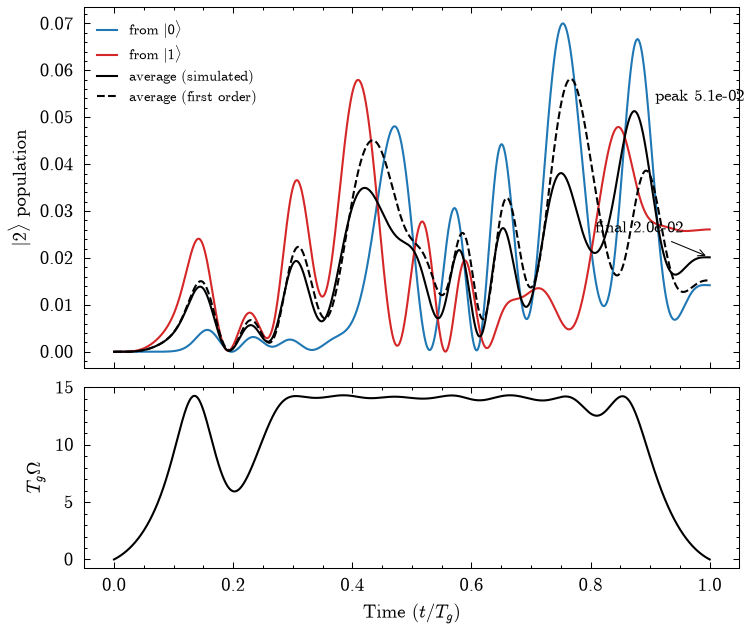

In [3]:
times = qutrit['times']
fig, axs = plt.subplots(2, 1, sharex=True, figsize=(5, 4.2), layout='constrained',
                        gridspec_kw={'height_ratios': [2, 1]})
axs[0].plot(times, qutrit['population_2_from_0'], color='tab:blue', label=r'from $|0\rangle$')
axs[0].plot(times, qutrit['population_2_from_1'], color='tab:red', label=r'from $|1\rangle$')
axs[0].plot(times, qutrit['leakage_trace'], color='k', label='average (simulated)')
axs[0].plot(times, first_order['leakage_trace'], 'k--', label='average (first order)')
peak = np.argmax(qutrit['leakage_trace'])
axs[0].annotate(f"peak {qutrit['peak_leakage']:.1e}", (times[peak], qutrit['peak_leakage']),
                xytext=(10, 5), textcoords='offset points', fontsize=8)
axs[0].annotate(f"final {qutrit['leakage']:.1e}", (times[-1], qutrit['leakage']),
                xytext=(-55, 12), textcoords='offset points', fontsize=8,
                arrowprops={'arrowstyle': '->', 'lw': 0.5})
axs[0].set_ylabel(r'$|2\rangle$ population')
axs[0].legend(fontsize=7)
axs[1].plot(times, control_dict['omega'], 'k')
axs[1].set_ylabel(r'$T_g\Omega$')
axs[1].set_xlabel(r'Time $(t/T_g)$')
plt.show()

## Leakage against gate time: calculated and simulated

Gate times from 20 to 200 ns. For each, the simulated final and peak
leakage are compared with two calculated quantities:

- **first order:** `drag.first_order_leakage`.
- **Fourier proxy:** `drag.estimate_leakage`,
  $\frac{\lambda^2}{4}\big|\int\varepsilon\,e^{iT_g\alpha s}ds\big|^2$. It
  ignores the qubit's own rotation, so it only ranks pulses.

The second panel is the error budget from the same simulations.

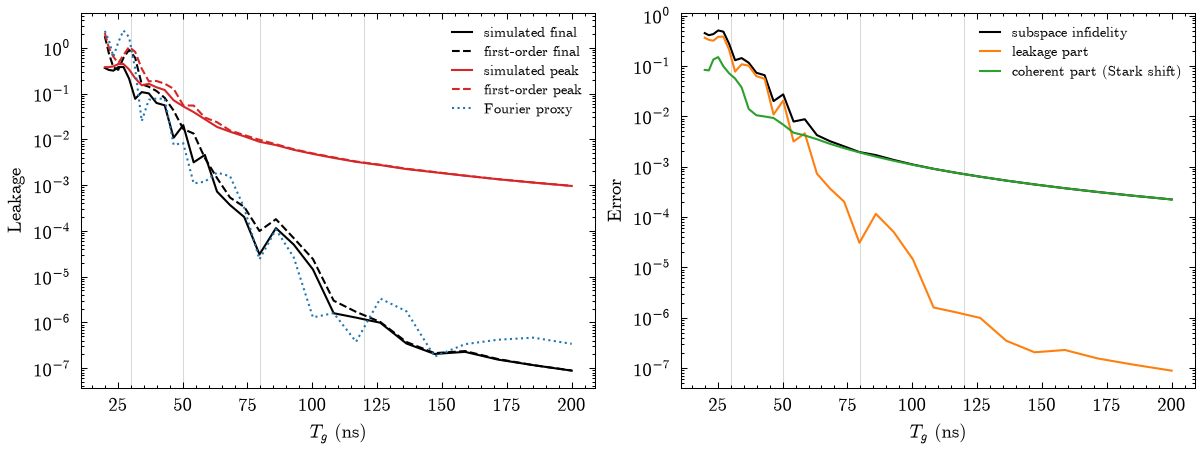

,simulated final,simulated peak,first-order final,first-order peak,Fourier proxy,subspace infidelity,coherent infidelity
T_g (ns),,,,,,,
20.000000,3.615189e-01,0.376462,1.799722e+00,2.091584,2.335796e+00,0.446822,0.083118
29.355985,2.121152e-01,0.335888,8.982624e-01,1.045598,1.703551e+00,0.276906,0.071532
43.088694,5.531995e-02,0.119534,8.061276e-02,0.164200,7.698923e-02,0.065184,0.009878
63.245553,7.238925e-04,0.018683,1.430711e-03,0.023722,1.877683e-03,0.004214,0.003493
92.831777,5.033747e-05,0.005908,6.954471e-05,0.006066,2.641586e-05,0.001355,0.001305
136.258414,3.477724e-07,0.002242,3.754207e-07,0.002284,1.760260e-06,0.000527,0.000527
200.000000,8.867829e-08,0.000959,8.953246e-08,0.000965,3.416330e-07,0.000223,0.000222


In [4]:
gate_times = np.geomspace(20, 200, 31)
rows = []
for gate_time in gate_times:
    value = xs.tg_alpha(gate_time)
    simulated = simulator.simulate_qutrit(control_dict, u_target, value, lam=xs.LAM)
    calculated = drag.first_order_leakage(control_dict, value, lam=xs.LAM)
    budget = xs.error_budget(simulated['u_final'], u_target)
    rows.append({
        'T_g (ns)': gate_time,
        'simulated final': simulated['leakage'],
        'simulated peak': simulated['peak_leakage'],
        'first-order final': calculated['leakage'],
        'first-order peak': calculated['leakage_trace'].max(),
        'Fourier proxy': drag.estimate_leakage(control_dict, value, lam=xs.LAM),
        'subspace infidelity': simulated['subspace_infidelity'],
        'coherent infidelity': budget['coherent_infidelity'],
    })
gate_time_scan = pd.DataFrame(rows).set_index('T_g (ns)')

fig, axs = plt.subplots(1, 2, figsize=(8, 3), layout='constrained')
scan = gate_time_scan
axs[0].semilogy(scan.index, scan['simulated final'], 'k-', label='simulated final')
axs[0].semilogy(scan.index, scan['first-order final'], 'k--', label='first-order final')
axs[0].semilogy(scan.index, scan['simulated peak'], '-', color='tab:red', label='simulated peak')
axs[0].semilogy(scan.index, scan['first-order peak'], '--', color='tab:red', label='first-order peak')
axs[0].semilogy(scan.index, scan['Fourier proxy'], ':', color='tab:blue', label='Fourier proxy')
axs[0].set_ylabel('Leakage')
axs[1].semilogy(scan.index, scan['subspace infidelity'], 'k-', label='subspace infidelity')
axs[1].semilogy(scan.index, scan['simulated final'], '-', color='tab:orange', label='leakage part')
axs[1].semilogy(scan.index, scan['coherent infidelity'], '-', color='tab:green',
                label='coherent part (Stark shift)')
axs[1].set_ylabel('Error')
for ax in axs:
    ax.set_xlabel(r'$T_g$ (ns)')
    for gate_time in xs.GATE_TIMES_NS:
        ax.axvline(gate_time, color='0.85', lw=0.5, zorder=0)
    ax.legend(fontsize=7)
plt.show()

gate_time_scan.loc[gate_time_scan.index[::5]]

**Reading the plots.**

- **Final leakage** falls by many orders of magnitude from 20 to 200 ns,
  with dips where the pulse spectrum has a node at the leakage frequency.
- **Peak leakage** falls much more slowly. The first-order calculation
  follows it closely.
- **Calculated final leakage** has the right trend from about 30 ns up.
  Where the final value is a small remainder of a much larger transient, it
  differs from the simulation by a factor of a few. Below about 25 ns the
  calculated leakage exceeds 1: the coupling is no longer a perturbation,
  and only the simulation counts. The missing piece in the calculation is
  the Stark shift of $|1\rangle$, which is second order and is left out.
- **Error budget:** below about 70 ns, leakage dominates the subspace
  infidelity. Above that, the coherent Stark-shift error dominates and
  falls only as $1/(T_g\alpha)^2$. That error is what the order-1 DRAG
  detuning term removes (notebook 03).

## Noise contours on the qutrit

The two-level contour from notebook 01 next to the qutrit contours at 50 and
120 ns. On the qutrit, the subspace infidelity includes leakage, and its
noiseless value sets a floor that the noise cannot go below.

In [5]:
qubit_contour = xs.load_result('contour_qubit_bare')
qutrit_contours = {}
for gate_time in (50.0, 120.0):
    qutrit_contours[gate_time] = noise_experiments.simult_source_experiment(
        control_dict, u_target, tg_alpha=xs.tg_alpha(gate_time), lam=xs.LAM)
    xs.save_result(f'contour_qutrit_bare_{int(gate_time)}ns', qutrit_contours[gate_time])

Static additive dephasing and multiplicative driving field experiment



Multiplicative driving field error:	 0.00 %
	 \---- Static additive dephasing error:	25.00 %

	 \---- Static additive dephasing error:	41.67 %

	 \---- Static additive dephasing error:	75.00 %

Multiplicative driving field error:	 8.33 %
	 \---- Static additive dephasing error:	 8.33 %

...

Multiplicative driving field error:	91.67 %
	 \---- Static additive dephasing error:	 0.00 %

	 \---- Static additive dephasing error:	33.33 %

	 \---- Static additive dephasing error:	66.67 %

	 \---- Static additive dephasing error:	83.33 %

Multiplicative driving field error:	100.00%


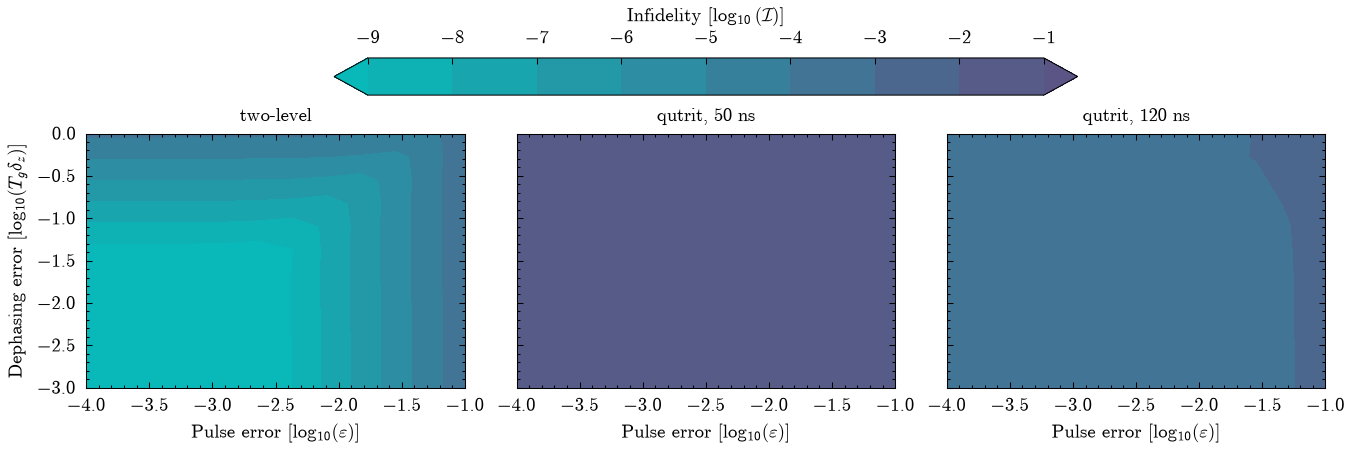

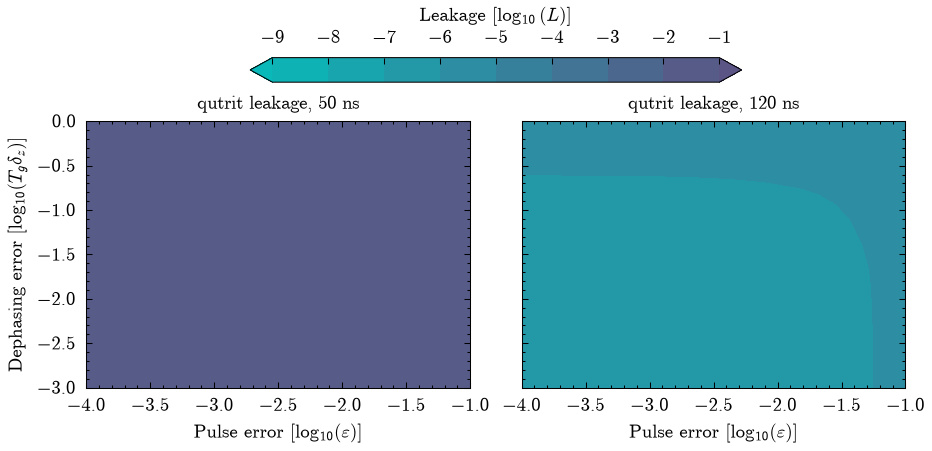

In [6]:
levels = np.arange(-9, 0)
fig, axs = plt.subplots(1, 3, figsize=(9, 3), layout='constrained', sharey=True)
panels = [('two-level', qubit_contour)] + [
    (f'qutrit, {int(t)} ns', c) for t, c in qutrit_contours.items()]
for ax, (title, result) in zip(axs, panels):
    contour = plottools.plot_noise_contour(result, levels=levels, ax=ax)
    ax.set_title(title, fontsize=9)
for ax in axs[1:]:
    ax.set_ylabel('')
fig.colorbar(contour, ax=axs, location='top', shrink=0.6,
             label=r'Infidelity $[\log_{10}(\mathcal{I})]$')
plt.show()

fig, axs = plt.subplots(1, 2, figsize=(6.2, 3), layout='constrained', sharey=True)
for ax, (gate_time, result) in zip(axs, qutrit_contours.items()):
    contour = plottools.plot_noise_contour(result, levels=np.arange(-9, 0), ax=ax,
                                           key='leakage_matrix')
    ax.set_title(f'qutrit leakage, {int(gate_time)} ns', fontsize=9)
axs[1].set_ylabel('')
fig.colorbar(contour, ax=axs, location='top', shrink=0.6,
             label=r'Leakage $[\log_{10}(L)]$')
plt.show()

**Reading the contours.**

- At 50 ns the qutrit map is flat at the noiseless floor: leakage plus
  Stark shift. The noise only shows at the largest errors, and the leakage
  barely depends on the noise.
- At 120 ns the floor is lower, and the dephasing and drive-error contours
  of the two-level map reappear above it.

## Is the dephasing robustness preserved on the qutrit?

The contours mix robustness with the floor. `sensitivity_sweep` removes the
floor: it compares the noisy gate with the noiseless gate of the same
system, restricted to the qubit subspace. On the qubit, the closed BARQ
curve gives no first-order dephasing term. On the qutrit, the Stark shift
$\propto\Omega^2/\alpha$ acts as an extra detuning that the curve was not
designed for. It opens the effective curve, and a first-order term returns.
That term shrinks as $1/(T_g\alpha)^2$.

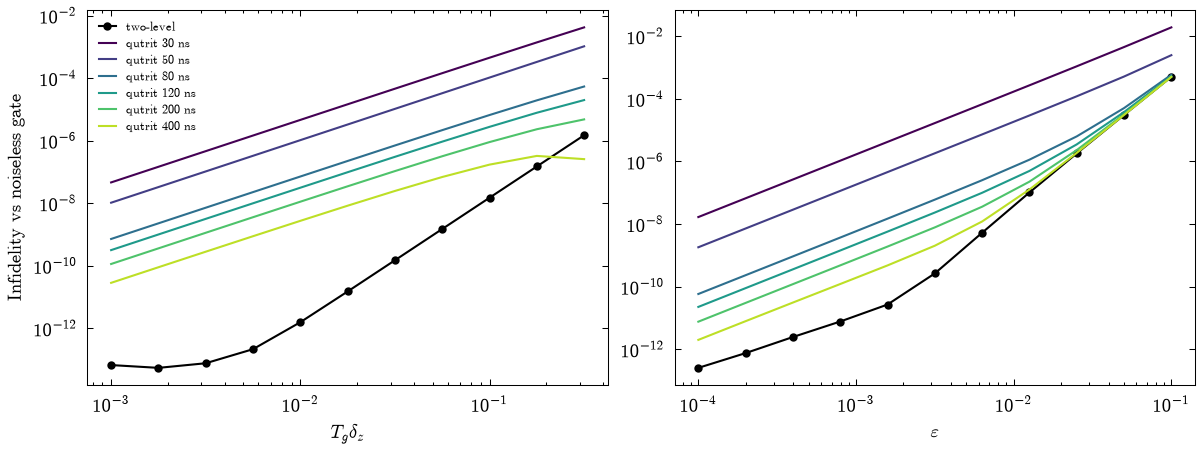

,dephasing S at T_g dz = 0.01,dephasing slope,amplitude S at eps = 0.001
T_g (ns),,,
30.0,4.593237e-06,1.986913,2.103204e-06
50.0,1.035150e-06,2.000384,2.280852e-07
80.0,7.116516e-08,1.961580,7.407373e-09
120.0,3.120783e-08,1.938411,2.857233e-09
200.0,1.114200e-08,1.888156,9.536291e-10
400.0,2.722803e-09,1.712998,2.395325e-10


In [7]:
tg_delta_z = np.logspace(-3, -0.5, 11)
epsilons = np.logspace(-4, -1, 11)
sweep_times = (30.0, 50.0, 80.0, 120.0, 200.0, 400.0)

qubit_dephasing = xs.sensitivity_sweep(control_dict, 'dephasing', tg_delta_z, u_target=u_target)
qubit_amplitude = xs.sensitivity_sweep(control_dict, 'amplitude', epsilons, u_target=u_target)
qutrit_dephasing, qutrit_amplitude = {}, {}
for gate_time in sweep_times:
    value = xs.tg_alpha(gate_time)
    qutrit_dephasing[gate_time] = xs.sensitivity_sweep(
        control_dict, 'dephasing', tg_delta_z, u_target=u_target, tg_alpha_value=value)
    qutrit_amplitude[gate_time] = xs.sensitivity_sweep(
        control_dict, 'amplitude', epsilons, u_target=u_target, tg_alpha_value=value)

colors = plt.cm.viridis(np.linspace(0, 0.9, len(sweep_times)))
fig, axs = plt.subplots(1, 2, figsize=(8, 3), layout='constrained')
axs[0].loglog(tg_delta_z, qubit_dephasing['sensitivity'], 'k-o', ms=3, label='two-level')
axs[1].loglog(epsilons, qubit_amplitude['sensitivity'], 'k-o', ms=3, label='two-level')
for color, gate_time in zip(colors, sweep_times):
    axs[0].loglog(tg_delta_z, qutrit_dephasing[gate_time]['sensitivity'], '-', color=color,
                  label=f'qutrit {int(gate_time)} ns')
    axs[1].loglog(epsilons, qutrit_amplitude[gate_time]['sensitivity'], '-', color=color,
                  label=f'qutrit {int(gate_time)} ns')
axs[0].set_xlabel(r'$T_g\delta_z$')
axs[1].set_xlabel(r'$\varepsilon$')
axs[0].set_ylabel('Infidelity vs noiseless gate')
axs[0].legend(fontsize=6)
plt.show()

pd.DataFrame({
    'dephasing S at T_g dz = 0.01': [np.interp(-2, np.log10(tg_delta_z), qutrit_dephasing[t]['sensitivity'])
                                     for t in sweep_times],
    'dephasing slope': [xs.loglog_slope(tg_delta_z, qutrit_dephasing[t]['sensitivity'])
                        for t in sweep_times],
    'amplitude S at eps = 0.001': [np.interp(-3, np.log10(epsilons), qutrit_amplitude[t]['sensitivity'])
                                   for t in sweep_times],
}, index=pd.Index(sweep_times, name='T_g (ns)'))

**Summary of notebook 02.**

- **Leakage.** At $T_g = 50$ ns ($T_g\alpha\approx-63$) the bare BARQ X gate
  leaks about $2\times10^{-2}$, after a transient peak of about
  $5\times10^{-2}$. Leakage falls very fast with gate time.
- **Calculated vs simulated leakage.** The first-order calculation
  reproduces the transient. It gets the final leakage to within a factor of
  a few where that final value is a small remainder.
- **Coherent error.** Beyond leakage, the Stark shift leaves an error
  inside the qubit that decays only as $1/(T_g\alpha)^2$.
- **Robustness.** The qutrit breaks the first-order dephasing robustness
  designed into the curve, by an amount that also falls as
  $1/(T_g\alpha)^2$.

Notebook 03 adds DRAG to remove the leakage and the Stark shift.